# Student Academic Performance Prediction (Colab Mini Project)
**Goal:** predict whether a student is likely to pass or fail using student demographic, family, and school-related attributes from the UCI Student Performance dataset.

**Pipeline:** data -> EDA -> model comparison (cross-validation) -> evaluation -> threshold tuning -> save model -> REST API (Flask, runs inside Colab) -> automated tests.

> Educational demonstration only. Predictions should not be used to label or limit individual students.

Run the cells top to bottom (Runtime -> Run all).

## 1. Setup and data

In [3]:
import io, zipfile, threading, warnings, json
import joblib, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, precision_recall_fscore_support)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
response = requests.get(url, timeout=30)
response.raise_for_status()
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    # Print ZIP contents to inspect structure if needed
    namelist = z.namelist()

    # Check if 'student.zip' is nested inside, or if student-mat.csv is directly accessible
    target_file = None
    for name in namelist:
        if name.endswith("student-mat.csv"):
            target_file = name
            break

    if target_file:
        with z.open(target_file) as f:
            df = pd.read_csv(f, sep=";")
    elif "student.zip" in namelist:
        # The dataset package might contain a nested 'student.zip'
        with z.open("student.zip") as nested_zip_bytes:
            with zipfile.ZipFile(io.BytesIO(nested_zip_bytes.read())) as z2:
                with z2.open("student-mat.csv") as f:
                    df = pd.read_csv(f, sep=";")
    else:
        raise FileNotFoundError(f"Could not find student-mat.csv or nested archive in: {namelist}")

# Predict pass/fail without using G1, G2, or G3 to avoid grade leakage.
df["target"] = (df["G3"] >= 10).astype(int)  # 1 = pass, 0 = fail
X = df.drop(columns=["G1", "G2", "G3", "target"])
y = df["target"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
X[cat_cols] = X[cat_cols].astype(object)

print("Rows, columns:", X.shape)
print("Pass rate:", round(y.mean(), 3))
print("Numeric:", len(num_cols), "| Categorical:", len(cat_cols))
df.head()

Rows, columns: (395, 30)
Pass rate: 0.671
Numeric: 13 | Categorical: 17


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,target
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,1


## 2. Exploratory analysis

Check the pass/fail balance and explore how absences relate to final pass/fail outcomes.

target
pass    265
fail    130
Name: count, dtype: int64 \n
target
pass    0.671
fail    0.329
Name: count, dtype: float64


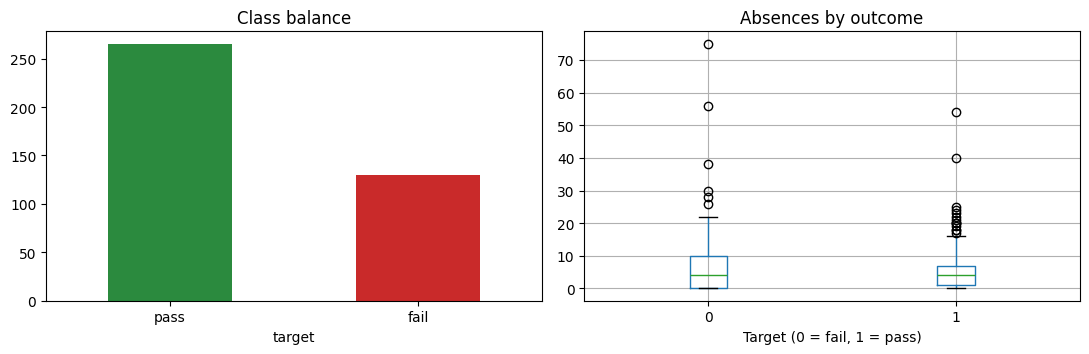

In [4]:
counts = y.value_counts().reindex([1, 0]).rename({1: "pass", 0: "fail"})
print(counts, "\\n")
print((counts / len(y)).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
counts.plot.bar(ax=ax[0], color=["#2b8a3e", "#c92a2a"], rot=0, title="Class balance")
df.boxplot(column="absences", by="target", ax=ax[1])
ax[1].set_title("Absences by outcome")
ax[1].set_xlabel("Target (0 = fail, 1 = pass)")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 3. Train/test split and model comparison

Use a stratified 80/20 split and compare Logistic Regression with Random Forest using five-fold cross-validation. Preprocessing is fitted inside each pipeline to reduce data leakage.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=250, class_weight="balanced",
                                           random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, clf in models.items():
    model_pipe = Pipeline([("pre", pre), ("clf", clf)])
    res = cross_validate(model_pipe, X_train, y_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    rows.append({"model": name, **{k.replace("test_", ""): v.mean()
                                  for k, v in res.items() if k.startswith("test_")}})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,0.684,0.790,0.726,0.756,0.689
RandomForest,0.712,0.717,0.943,0.815,0.679


## 4. Fit the best model and evaluate on the held-out test set

Select the model with the highest cross-validated F1 score, then evaluate it once on the held-out test data.

Selected model: RandomForest
              precision    recall  f1-score   support

        fail       0.56      0.19      0.29        26
        pass       0.70      0.92      0.80        53

    accuracy                           0.68        79
   macro avg       0.63      0.56      0.54        79
weighted avg       0.65      0.68      0.63        79

ROC-AUC: 0.661


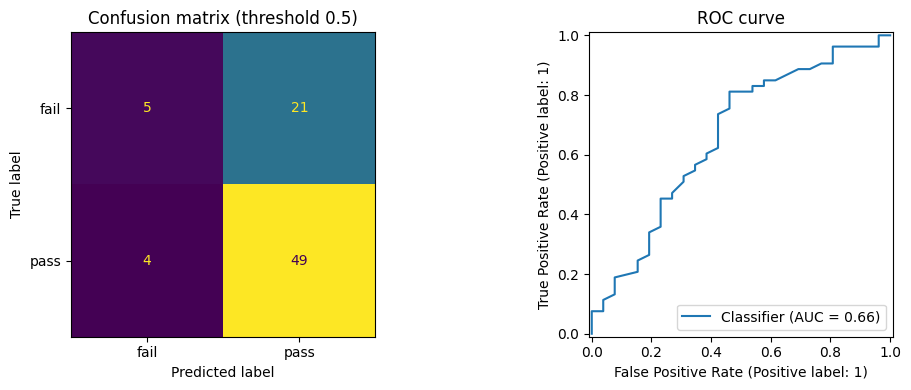

In [7]:
best_name = cv_table["f1"].idxmax()
print("Selected model:", best_name)
pipe = Pipeline([("pre", pre), ("clf", models[best_name])]).fit(X_train, y_train)

proba = pipe.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print(classification_report(y_test, pred, labels=[0, 1], target_names=["fail", "pass"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                       display_labels=["fail", "pass"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (threshold 0.5)")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1])
ax[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

## 5. Threshold tuning

The probability threshold changes the trade-off between identifying students at risk of failing and avoiding false alarms. Choose a threshold using cross-validated predictions from the training data only, then evaluate it on the test set.

In [8]:
cv_proba = cross_val_predict(
    Pipeline([("pre", pre), ("clf", models[best_name])]),
    X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.arange(0.2, 0.81, 0.05)
rows = []
for t in thresholds:
    p, r, f, _ = precision_recall_fscore_support(
        y_train, (cv_proba >= t).astype(int), average="binary", zero_division=0)
    rows.append({"threshold": round(t, 2), "precision": p, "recall": r, "f1": f})
th = pd.DataFrame(rows).set_index("threshold").round(3)
print(th)
BEST_T = float(th["f1"].idxmax())
print("\\nChosen threshold:", BEST_T)

pred_t = (proba >= BEST_T).astype(int)
print(classification_report(y_test, pred_t, labels=[0, 1],
                            target_names=["fail", "pass"], zero_division=0))

           precision  recall     f1
threshold                          
0.20           0.671   1.000  0.803
0.25           0.673   1.000  0.805
0.30           0.673   1.000  0.805
0.35           0.674   0.995  0.804
0.40           0.683   0.995  0.810
0.45           0.691   0.972  0.808
0.50           0.714   0.953  0.816
0.55           0.722   0.882  0.794
0.60           0.740   0.792  0.765
0.65           0.755   0.712  0.733
0.70           0.790   0.585  0.672
0.75           0.817   0.420  0.555
0.80           0.852   0.245  0.381
\nChosen threshold: 0.5
              precision    recall  f1-score   support

        fail       0.56      0.19      0.29        26
        pass       0.70      0.92      0.80        53

    accuracy                           0.68        79
   macro avg       0.63      0.56      0.54        79
weighted avg       0.65      0.68      0.63        79



## 6. Save the model

In [9]:
defaults = {c: (float(X_train[c].median()) if c in num_cols else X_train[c].mode()[0])
            for c in X.columns}
bundle = {"pipeline": pipe, "columns": X.columns.tolist(), "defaults": defaults,
          "threshold": BEST_T, "model_name": best_name}
joblib.dump(bundle, "student_performance_model.joblib")
print("Saved student_performance_model.joblib")

Saved student_performance_model.joblib


## 7. REST API (Flask running inside Colab)

The API accepts a JSON object containing student feature values. Fields not provided use training-set defaults. The output is a model estimate, not a definitive judgment about a student.

In [10]:
from flask import Flask, jsonify, request
from werkzeug.serving import make_server
import threading
import joblib
import pandas as pd

api = Flask(__name__)
B = joblib.load("student_performance_model.joblib")

@api.get("/api/health")
def health():
    return jsonify({"status": "ok", "model": B["model_name"], "threshold": B["threshold"]})

@api.post("/api/predict")
def predict():
    record = request.get_json(silent=True)
    if not isinstance(record, dict):
        return jsonify({"error": "Send a JSON object of feature names and values."}), 400
    unknown = [k for k in record if k not in B["columns"]]
    if unknown:
        return jsonify({"error": f"Unknown fields: {unknown}"}), 400
    row = {**B["defaults"], **{k: v for k, v in record.items() if v not in (None, "")}}
    try:
        frame = pd.DataFrame([row], columns=B["columns"])
        p = float(B["pipeline"].predict_proba(frame)[0][1])
    except Exception:
        return jsonify({"error": "Could not process the supplied values."}), 400
    return jsonify({"prediction": "pass" if p >= B["threshold"] else "fail",
                    "estimated_pass_probability": round(p, 4),
                    "notice": "Educational demonstration only; not a definitive student assessment."})

if "server" in globals():
    try:
        server.shutdown()
    except Exception:
        pass

server = make_server("127.0.0.1", 5000, api)
threading.Thread(target=server.serve_forever, daemon=True).start()
print("API running on http://127.0.0.1:5000")

API running on http://127.0.0.1:5000


In [11]:
print(requests.get("http://127.0.0.1:5000/api/health").json())

sample = json.loads(X_test.iloc[[0]].to_json(orient="records"))[0]
print("Actual outcome:", "pass" if y_test.iloc[0] else "fail")
print(requests.post("http://127.0.0.1:5000/api/predict", json=sample).json())

# Partial input works because missing fields use training defaults.
print(requests.post("http://127.0.0.1:5000/api/predict",
                    json={"age": 17, "absences": 4, "studytime": 2}).json())

# Invalid input returns HTTP 400.
r = requests.post("http://127.0.0.1:5000/api/predict", json=[1, 2])
print(r.status_code, r.json())

INFO:werkzeug:127.0.0.1 - - [22/Oct/2026 02:59:14] "GET /api/health HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [22/Oct/2026 02:59:14] "POST /api/predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [22/Oct/2026 02:59:14] "POST /api/predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [22/Oct/2026 02:59:14] "POST /api/predict HTTP/1.1" 400 -


{'model': 'RandomForest', 'status': 'ok', 'threshold': 0.5}
Actual outcome: pass
{'estimated_pass_probability': 0.532, 'notice': 'Educational demonstration only; not a definitive student assessment.', 'prediction': 'pass'}
{'estimated_pass_probability': 0.76, 'notice': 'Educational demonstration only; not a definitive student assessment.', 'prediction': 'pass'}
400 {'error': 'Send a JSON object of feature names and values.'}


## 8. Automated tests

In [12]:
def run_tests():
    c = api.test_client()
    assert c.get("/api/health").status_code == 200
    ok = c.post("/api/predict", json=sample)
    assert ok.status_code == 200
    body = ok.get_json()
    assert body["prediction"] in ("pass", "fail")
    assert 0 <= body["estimated_pass_probability"] <= 1
    assert c.post("/api/predict", json=[1, 2]).status_code == 400
    assert c.post("/api/predict", json={"not_a_field": 1}).status_code == 400
    assert c.post("/api/predict", data="not json").status_code == 400
    print("All API tests passed")

run_tests()

All API tests passed


## 9. Summary for your report

- **Problem:** binary classification of student outcomes (pass/fail), derived from final grade G3 where G3 >= 10 is a pass.
- **Dataset:** UCI Student Performance dataset; this notebook uses the Mathematics (`student-mat.csv`) subset.
- **Features:** demographic, family, school, study, and attendance-related fields. G1, G2, and G3 are excluded from the inputs to avoid using grades that would reveal the outcome.
- **Method:** missing-value imputation, numeric scaling, one-hot encoding, Logistic Regression and Random Forest compared with five-fold stratified cross-validation.
- **Evaluation:** precision, recall, F1, ROC-AUC, confusion matrix, and threshold tuning.
- **Deployment:** saved pipeline using joblib and a Flask REST API with input validation and automated tests.
- **Limitations:** the dataset is relatively small and may not represent other schools or student populations. Predictions can be wrong and should support, not replace, professional judgment or student conversations.